CELLS below ran the Wilson 95% confidence interval to check for statistical significance

The 18 weekly bands covering 0-18 weeks were identified by column-name pattern and summed to give the number of patients waiting 18 weeks or less

In [1]:
import re
import numpy as np
import pandas as pd



rtt = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  parse_dates=["period"])
df_ci = rtt.copy()


# Bands gt_00_to_01 ... gt_17_to_18 = waited up to 18 weeks
within_cols = [c for c in df_ci.columns
               if (m := re.match(r"gt_(\d+)_to_(\d+)_weeks", c)) and int(m.group(2)) <= 18]
print(len(within_cols), within_cols[0], "...", within_cols[-1])   # expect 18 columns

df_ci["within_18"] = df_ci[within_cols].sum(axis=1)

18 gt_00_to_01_weeks_sum_1 ... gt_17_to_18_weeks_sum_1


In [2]:
#Create a function for the Wilson 95% confidence interval
def wilson_ci(successes, total, z=1.96):
    """95% Wilson confidence interval for a proportion, returned as percentages."""
    p = successes / total
    denom = 1 + z**2 / total
    centre = (p + z**2 / (2 * total)) / denom
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denom
    return p * 100, (centre - margin) * 100, (centre + margin) * 100

def add_ci(table):
    table["pct_within_18"], table["ci_low"], table["ci_high"] = wilson_ci(table["within_18"], table["total_all"])
    return table.round(2)

In [3]:
#National Performance by Month with CI
national = add_ci(df_ci.groupby("period")[["within_18", "total_all"]].sum())
print(national)

#National performance improved over the year and reached the 65% interim target
#from march 2026. Still far from the 92% standard

            within_18  total_all  pct_within_18  ci_low  ci_high
period                                                          
2025-09-01  4522668.0    7329574          61.70   61.67    61.74
2025-10-01  4523866.0    7337076          61.66   61.62    61.69
2025-11-01  4429395.0    7191310          61.59   61.56    61.63
2025-12-01  4440594.0    7231880          61.40   61.37    61.44
2026-01-01  4412147.0    7187677          61.38   61.35    61.42
2026-02-01  4472365.0    7156212          62.50   62.46    62.53
2026-03-01  4596622.0    7045510          65.24   65.21    65.28
2026-04-01  4623405.0    7123980          64.90   64.86    64.93
2026-05-01  4706017.0    7184233          65.50   65.47    65.54
2026-06-01  4721677.0    7178718          65.77   65.74    65.81
2026-07-01  4673731.0    7162692          65.25   65.22    65.29
2026-08-01  4684589.0    7189213          65.16   65.13    65.20


In [4]:
#SPECIALTIES IN THE LATEST MONTH,WITH CI
latest = df_ci["period"].max()
spec = add_ci(df_ci[df_ci["period"] == latest]
              .groupby("treatment_function_name")[["within_18", "total_all"]].sum())
spec = spec.sort_values("pct_within_18")
print(f"Latest month: {latest:%B %Y}")
print(spec)
#every specialty is below the 92% standard. 9 out of 23 are below the 65% interim target,
#ranging from 53.8% in oral surgery to 84.3% in elderly medicine

#Between September 2025 and August 2026, the share of patients waiting 18 weeks or less rose
#from 61.7% to 65.2% (95% CI 65.1–65.2%). Most of the improvement happened in a single step between
#February and March 2026, when performance reached the 65% interim target, and it has stayed close
#to that level since. However, around 1 in 3 patients (about 2.5 million people) were still
#waiting longer than 18 weeks, leaving performance 27 points below the 92% constitutional standard.

Latest month: August 2026
                                   within_18  total_all  pct_within_18  \
treatment_function_name                                                  
Oral Surgery Service                170233.0     316357          53.81   
Ear Nose and Throat Service         335098.0     590233          56.77   
Plastic Surgery Service              65108.0     109605          59.40   
Gynaecology Service                 349558.0     586582          59.59   
Trauma and Orthopaedic Service      518052.0     851183          60.86   
Neurosurgical Service                33945.0      54748          62.00   
Neurology Service                   129563.0     208030          62.28   
General Surgery Service             243185.0     384914          63.18   
Urology Service                     238017.0     367027          64.85   
Other - Paediatric Services         212990.0     322905          65.96   
Other - Surgical Services           317611.0     474806          66.89   
Cardiology S

In [5]:
#IS THE WORST SPECIALITY SIGNIFICANTLY DIFFERENT FROM THE REST
worst = spec.index[0]
a = spec.loc[worst]
rest = spec.drop(worst)[["within_18", "total_all"]].sum()

p1, p2 = a["within_18"] / a["total_all"], rest["within_18"] / rest["total_all"]
diff = (p1 - p2) * 100
se = np.sqrt(p1 * (1 - p1) / a["total_all"] + p2 * (1 - p2) / rest["total_all"]) * 100
print(f"{worst}: {p1*100:.1f}% vs all other specialties {p2*100:.1f}%")
print(f"Difference: {diff:.1f} points (95% CI {diff - 1.96*se:.1f} to {diff + 1.96*se:.1f})")



Oral Surgery Service: 53.8% vs all other specialties 65.7%
Difference: -11.9 points (95% CI -12.1 to -11.7)


In August 2026, 53.8% of Oral Surgery patients had waited 18 weeks or less, compared with 65.7% across all
other specialties: a difference of 11.9 percentage points (95% CI 11.7 to 12.1). The interval does not include zero,
so the gap is very unlikely to be due to chance. In practical terms, nearly half of Oral Surgery patients 
had waited longer than 18 weeks, compared with about one in three elsewhere, making them about 35% more likely
to be a long waiter.

CAVEAT
Because the data covers everyone on the waiting list rather than a sample, confidence intervals
#are interpreted as uncertainty in the underlying process; with lists this large, even small differences
#are statistically significant, so the size of the gap matters more than its significance.

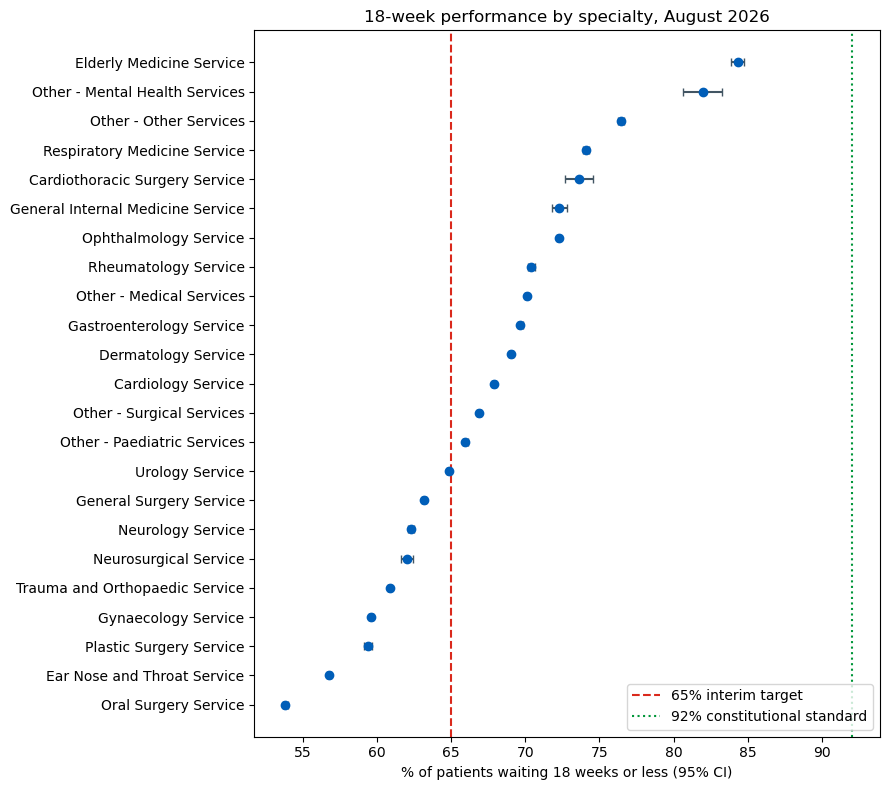

In [6]:
#CHART WITH ERROR BARS
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))
ax.errorbar(spec["pct_within_18"], spec.index,
            xerr=[spec["pct_within_18"] - spec["ci_low"], spec["ci_high"] - spec["pct_within_18"]],
            fmt="o", color="#005EB8", ecolor="#425563", capsize=3)
ax.axvline(65, color="#DA291C", linestyle="--", label="65% interim target")
ax.axvline(92, color="#009639", linestyle=":", label="92% constitutional standard")
ax.set_xlabel("% of patients waiting 18 weeks or less (95% CI)")
ax.set_title(f"18-week performance by specialty, {latest:%B %Y}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
#SAVE FOR ONWARD TRANSMISSION TO POWER BI
spec.reset_index().to_csv("../data/rtt_combined_sep25_aug26.csv", index=False)